In [10]:
# Real-Time Anomaly Detection in Financial Transactions

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    average_precision_score
)

print("All libraries imported successfully!")



All libraries imported successfully!


In [11]:
# Load the credit card transaction dataset

df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Check normal and fraudulent transactions

print("Transaction Class Distribution:")
print(df["Class"].value_counts())

print("\nPercentage Distribution:")
print(df["Class"].value_counts(normalize=True) * 100)

Transaction Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Percentage Distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


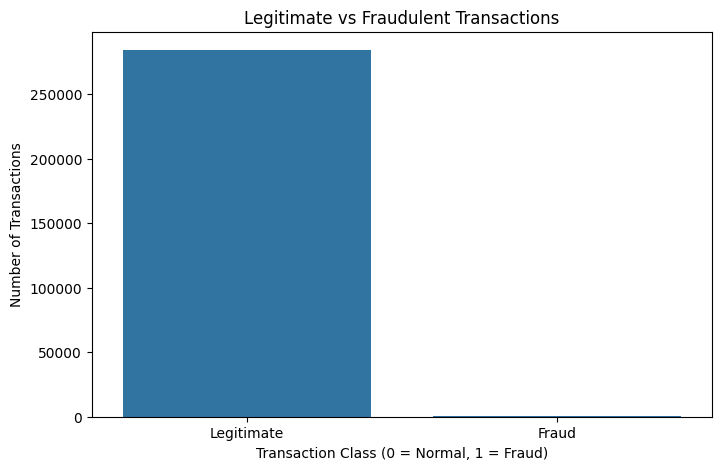

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(x="Class", data=df)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()


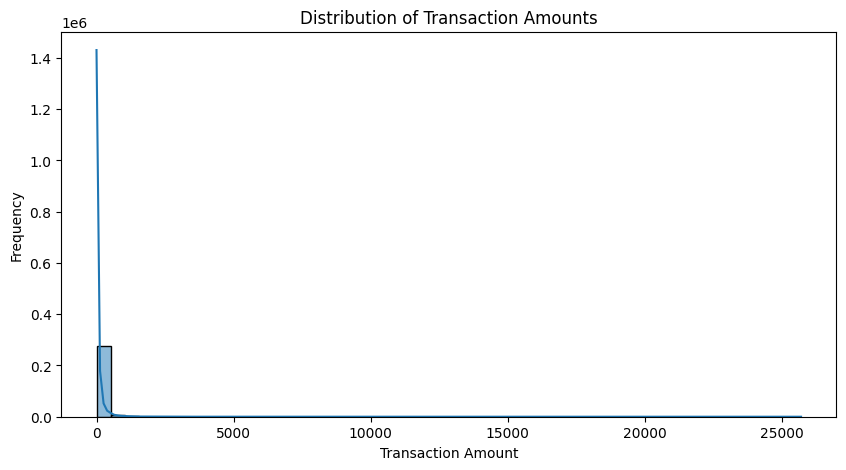

In [5]:
# Analyze transaction amounts

plt.figure(figsize=(10, 5))

sns.histplot(df["Amount"], bins=50, kde=True)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

In [13]:
# Scale transaction Amount using RobustScaler

amount_scaler = RobustScaler()

df["Amount_scaled"] = amount_scaler.fit_transform(
    df[["Amount"]]
)

print("RobustScaler applied successfully!")

print("\nOriginal Amount:")
print(df["Amount"].describe())

print("\nScaled Amount:")
print(df["Amount_scaled"].describe())

RobustScaler applied successfully!

Original Amount:
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

Scaled Amount:
count    284807.000000
mean          0.927124
std           3.495006
min          -0.307413
25%          -0.229162
50%           0.000000
75%           0.770838
max         358.683155
Name: Amount_scaled, dtype: float64


In [7]:
# Prepare features and target

X = df.drop(columns=["Class", "Amount"])
y = df["Class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Features prepared successfully!")

Feature shape: (284807, 30)
Target shape: (284807,)
Features prepared successfully!


In [14]:
# Train Isolation Forest on normal transactions

normal_data = X[y == 0]

iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.002,
    random_state=42,
    n_jobs=-1
)

iso_forest.fit(normal_data)

print("Isolation Forest trained successfully!")
print("Training transactions:", normal_data.shape[0])

NameError: name 'X' is not defined

In [6]:
# Predict anomalies using Isolation Forest

iso_predictions = iso_forest.predict(X)

# Convert -1 (anomaly) to 1 and +1 (normal) to 0
iso_predictions = (iso_predictions == -1).astype(int)

# Calculate evaluation metrics
print("ISOLATION FOREST PERFORMANCE")
print("--------------------------------")

print("Precision:", precision_score(y, iso_predictions))
print("Recall:", recall_score(y, iso_predictions))
print("F1 Score:", f1_score(y, iso_predictions))

print("\nClassification Report:")
print(classification_report(y, iso_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y, iso_predictions))

NameError: name 'iso_forest' is not defined

In [9]:
# Isolation Forest Confusion Matrix

iso_cm = confusion_matrix(y, iso_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    iso_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Isolation Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

NameError: name 'confusion_matrix' is not defined

In [8]:
# Train Local Outlier Factor

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.002,
    novelty=True,
    n_jobs=-1
)

lof_model.fit(normal_data)

print("Local Outlier Factor trained successfully!")
print("Training transactions:", normal_data.shape[0])


NameError: name 'LocalOutlierFactor' is not defined

In [7]:
# Train Local Outlier Factor

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.002,
    novelty=True,
    n_jobs=-1
)

lof_model.fit(normal_data)

print("Local Outlier Factor trained successfully!")
print("Training transactions:", normal_data.shape[0])


NameError: name 'LocalOutlierFactor' is not defined

In [2]:
lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.002,
    novelty=True,
    n_jobs=-1
)

lof_model.fit(normal_data)

print("LOF trained successfully!")

NameError: name 'LocalOutlierFactor' is not defined

In [15]:
normal_data = X[y == 0]

print("Normal transactions:", normal_data.shape[0])


NameError: name 'X' is not defined

In [16]:
# Restore project data and preprocessing

import pandas as pd
import numpy as np

from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Load dataset
df = pd.read_csv("creditcard.csv")

# Apply RobustScaler
scaler = RobustScaler()
df["Amount_scaled"] = scaler.fit_transform(df[["Amount"]])

# Prepare features and target
X = df.drop(columns=["Class", "Amount"])
y = df["Class"]

# Select normal transactions
normal_data = X[y == 0]

print("Project data restored successfully!")
print("Features:", X.shape)
print("Target:", y.shape)
print("Normal transactions:", normal_data.shape[0])

Project data restored successfully!
Features: (284807, 30)
Target: (284807,)
Normal transactions: 284315


In [17]:
# Train LOF using a sample of normal transactions

normal_sample = normal_data.sample(
    n=20000,
    random_state=42
)

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.002,
    novelty=True,
    n_jobs=-1
)

lof_model.fit(normal_sample)

print("LOF trained successfully!")
print("Training sample:", normal_sample.shape[0])

LOF trained successfully!
Training sample: 20000


In [18]:
# Evaluate LOF on a test sample

normal_test = normal_data.sample(n=5000, random_state=10)
fraud_test = X[y == 1]

X_test = pd.concat([normal_test, fraud_test])
y_test = pd.Series(
    [0] * len(normal_test) + [1] * len(fraud_test),
    index=X_test.index
)

lof_predictions = (lof_model.predict(X_test) == -1).astype(int)

print("LOF PERFORMANCE")
print("-------------------------")
print("Precision:", precision_score(y_test, lof_predictions))
print("Recall:", recall_score(y_test, lof_predictions))
print("F1 Score:", f1_score(y_test, lof_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lof_predictions))

C:\Users\PRIME\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


LOF PERFORMANCE
-------------------------
Precision: 0.2727272727272727
Recall: 0.006097560975609756
F1 Score: 0.011928429423459244

Confusion Matrix:
[[4992    8]
 [ 489    3]]


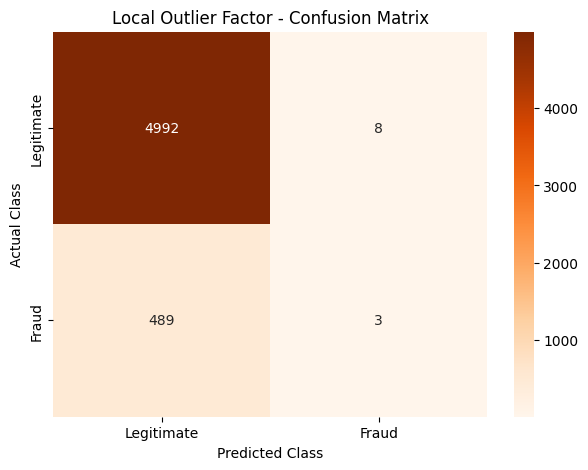

In [19]:
# LOF Confusion Matrix

lof_cm = confusion_matrix(y_test, lof_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    lof_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Local Outlier Factor - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [20]:
# Train Isolation Forest on the same training sample

iso_comparison = IsolationForest(
    n_estimators=100,
    contamination=0.002,
    random_state=42,
    n_jobs=-1
)

iso_comparison.fit(normal_sample)

# Predict on the same test data
iso_test_predictions = (
    iso_comparison.predict(X_test) == -1
).astype(int)

# Compare performance
print("ISOLATION FOREST PERFORMANCE")
print("-----------------------------")
print("Precision:", precision_score(y_test, iso_test_predictions))
print("Recall:", recall_score(y_test, iso_test_predictions))
print("F1 Score:", f1_score(y_test, iso_test_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, iso_test_predictions))

ISOLATION FOREST PERFORMANCE
-----------------------------
Precision: 0.89375
Recall: 0.29065040650406504
F1 Score: 0.4386503067484663

Confusion Matrix:
[[4983   17]
 [ 349  143]]


In [21]:
# Compare Isolation Forest and LOF

comparison = pd.DataFrame({
    "Algorithm": ["Isolation Forest", "Local Outlier Factor"],
    "Precision": [
        precision_score(y_test, iso_test_predictions),
        precision_score(y_test, lof_predictions)
    ],
    "Recall": [
        recall_score(y_test, iso_test_predictions),
        recall_score(y_test, lof_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, iso_test_predictions),
        f1_score(y_test, lof_predictions)
    ]
})

comparison

,Algorithm,Precision,Recall,F1 Score
0,Isolation Forest,0.893750,0.290650,0.438650
1,Local Outlier Factor,0.272727,0.006098,0.011928


C:\Users\PRIME\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


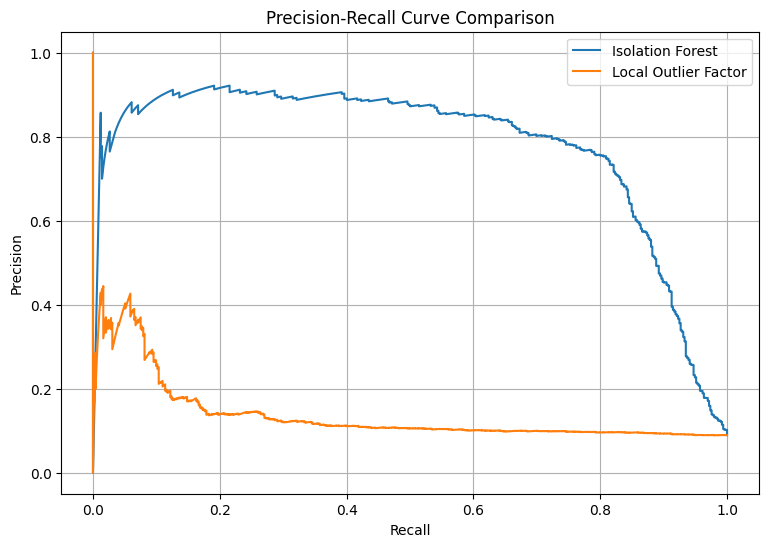

Isolation Forest AP: 0.7805606500771667
LOF AP: 0.13762746326629668


In [22]:
# Precision-Recall Curve Comparison

# Get anomaly scores (lower scores indicate more anomalous)
iso_scores = -iso_comparison.decision_function(X_test)
lof_scores = -lof_model.decision_function(X_test)

# Calculate precision and recall
iso_precision, iso_recall, _ = precision_recall_curve(
    y_test, iso_scores
)

lof_precision, lof_recall, _ = precision_recall_curve(
    y_test, lof_scores
)

# Plot curves
plt.figure(figsize=(9, 6))

plt.plot(
    iso_recall, iso_precision,
    label="Isolation Forest"
)

plt.plot(
    lof_recall, lof_precision,
    label="Local Outlier Factor"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid()
plt.show()

print("Isolation Forest AP:",
      average_precision_score(y_test, iso_scores))

print("LOF AP:",
      average_precision_score(y_test, lof_scores))

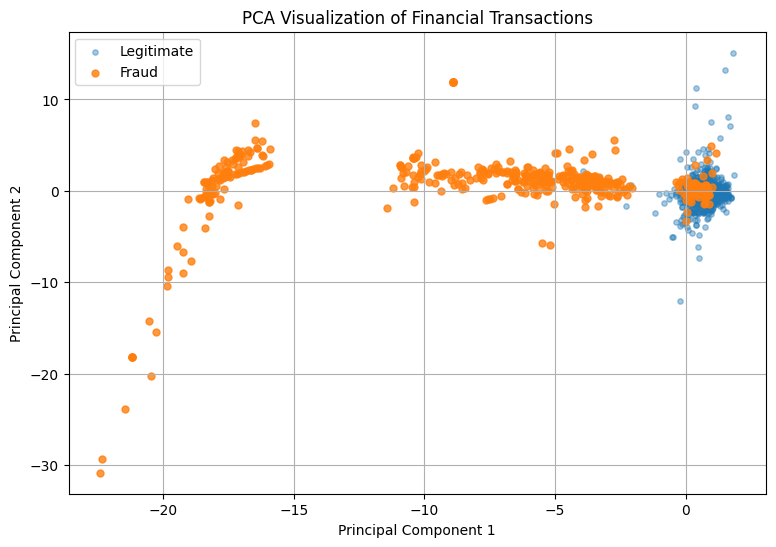

Explained variance: 0.362758737225232


In [23]:
# PCA visualization of transactions

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Scale features for visualization
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X_test)

# Reduce features to 2 dimensions
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Create visualization
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[y_test.values == 0, 0],
    X_pca[y_test.values == 0, 1],
    label="Legitimate",
    alpha=0.4,
    s=15
)

plt.scatter(
    X_pca[y_test.values == 1, 0],
    X_pca[y_test.values == 1, 1],
    label="Fraud",
    alpha=0.8,
    s=25
)

plt.title("PCA Visualization of Financial Transactions")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid()
plt.show()

print("Explained variance:", pca.explained_variance_ratio_.sum())

In [24]:
# Isolation Forest threshold tuning

precision_values, recall_values, thresholds = precision_recall_curve(
    y_test, iso_scores
)

# Calculate F1 score for each threshold
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

# Find the best threshold
best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("BEST ISOLATION FOREST THRESHOLD")
print("--------------------------------")
print("Threshold:", best_threshold)
print("Precision:", precision_values[best_index])
print("Recall:", recall_values[best_index])
print("F1 Score:", f1_values[best_index])

BEST ISOLATION FOREST THRESHOLD
--------------------------------
Threshold: -0.10622483231164548
Precision: 0.7537878787878788
Recall: 0.8089430894308943
F1 Score: 0.7803921568128074


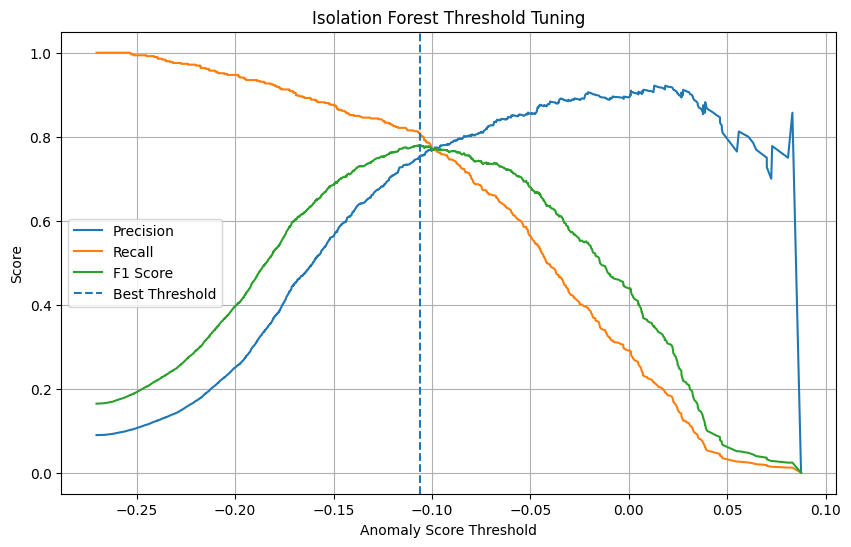

In [25]:
# Plot Precision, Recall and F1 against threshold

plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision_values[:-1], label="Precision")
plt.plot(thresholds, recall_values[:-1], label="Recall")
plt.plot(thresholds, f1_values, label="F1 Score")

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Best Threshold"
)

plt.xlabel("Anomaly Score Threshold")
plt.ylabel("Score")
plt.title("Isolation Forest Threshold Tuning")
plt.legend()
plt.grid()
plt.show()

In [26]:
# Apply the tuned Isolation Forest threshold

tuned_predictions = (iso_scores >= best_threshold).astype(int)

print("TUNED ISOLATION FOREST RESULTS")
print("--------------------------------")

print("Precision:", precision_score(y_test, tuned_predictions))
print("Recall:", recall_score(y_test, tuned_predictions))
print("F1 Score:", f1_score(y_test, tuned_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_predictions))


TUNED ISOLATION FOREST RESULTS
--------------------------------
Precision: 0.7537878787878788
Recall: 0.8089430894308943
F1 Score: 0.7803921568627451

Confusion Matrix:
[[4870  130]
 [  94  398]]


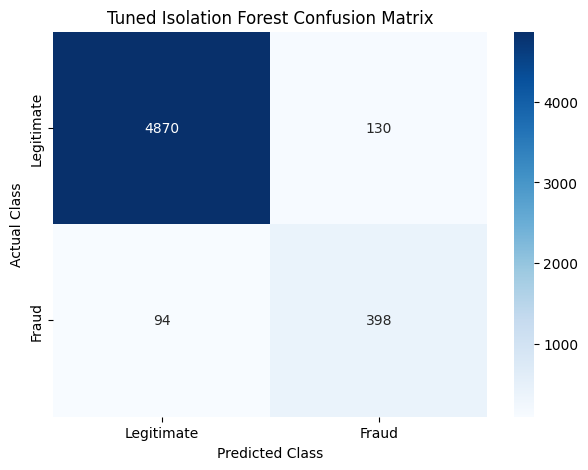

In [27]:
# Tuned Isolation Forest Confusion Matrix

cm = confusion_matrix(y_test, tuned_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Tuned Isolation Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()